<h2 style="font-weight:600;color:#4f7a9b">K-means</h2>

K-means is a general-purpose, even cluster size, flat geometry, not too many clusters **inductive** clustering model.

The algorithm divides a set of N samples into K disjoint clusters, each cluster described by the mean $\mu_j$ of the samples inside it. These means are called **centroids**.

The centroids are chosen so that they minimize the **inertia** i.e. the within-cluster sum-of-squares criterion:

$$
\sum_{i=0}^{N-1} \min_{\mu_j \in C}
\left(
\|x_i - \mu_j\|^2
\right)
$$

where

- $N$= number of samples (data points)
- $x_i$ = the $i$-th sample
- $C$ = the set of clusters
- $\mu_j$ = centroid of cluster $j$
- $|x_i - \mu_j|$ = Euclidean distance between sample and centroid
- $\min$ = choose the nearest centroid

<span style="font-weight:600;color:#4f7a9b">DRAWBACKS</span>

- K means works better with clusters that are **convex** and **isotropic** (roughly spherical in shape and same spread in all directions). If the clusters are elongated or irregular, it performs poorly.

- Inertia is not a normalized metric. We only know that lower values are better than higher ones. However, in very high-dimensional spaces, Euclidean distances tend to get inflated. In such cases we use a **dimensionality reduction** algorithm (PCA) before using K-means clustering.

> **CONVEX SHAPE**<br/>
    For any two points inside the shape, the straight line that connects the points, stays entirely inside the shape.<br/>
> **ISOTROPIC SHAPE**<br/>
    The shape has roughly the same spread in all directions.

<h2 style="font-weight:600;color:#4f7a9b">Demonstration of K-means assumptions</h2>

<h4 style="font-weight:600;color:#4f7a9b">1. Demonstration of K-means assumptions</h4>

To obtain **anisotropic** (elliptical) blobs, we define a linear transformation.

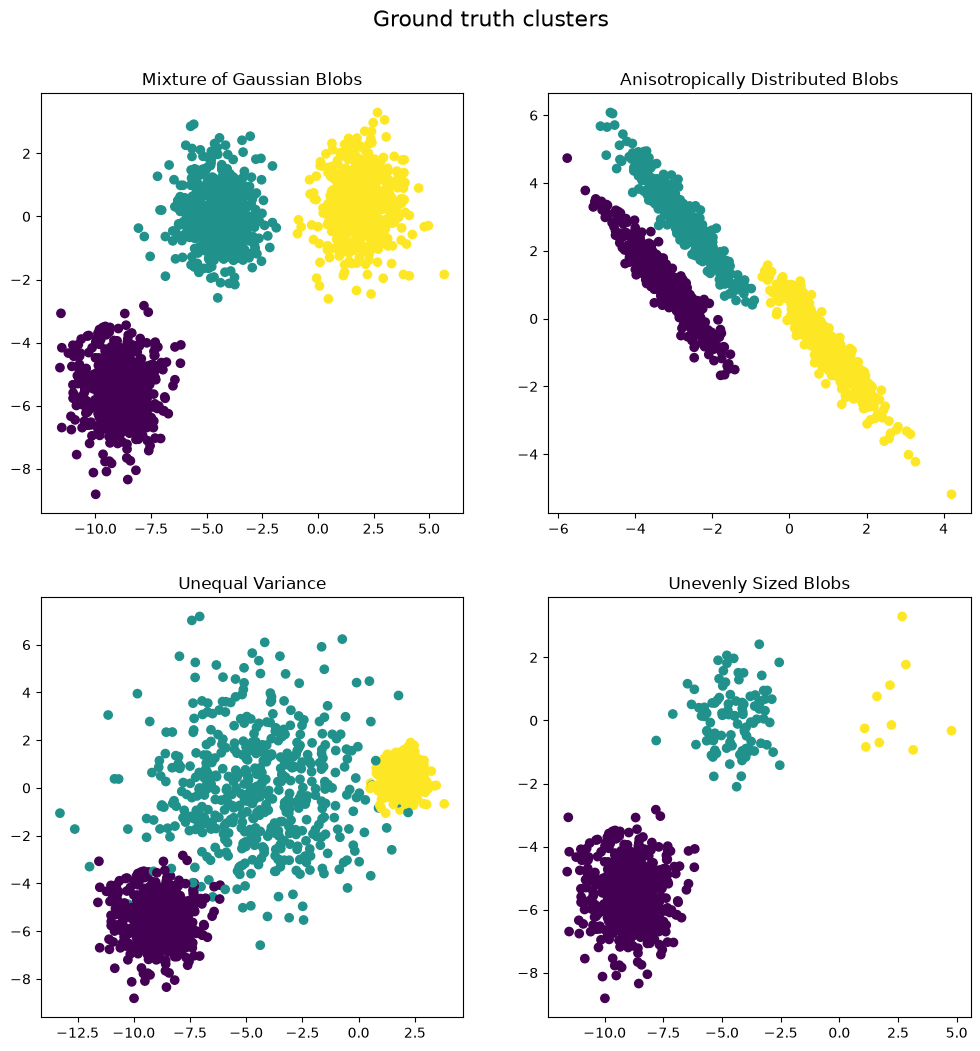

In [25]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.datasets import make_blobs

n_samples = 1_500
random_state = 170
transformation = [
    [0.60834549, -0.63667341],
    [-0.40887718, 0.85253229],
]

# Isotropic (spherical) blobs
X, y = make_blobs(n_samples=n_samples, random_state=random_state)
# Anisotropic blobs
X_aniso = np.dot(X, transformation)
# Unequal variance
X_varied, y_varied = make_blobs(n_samples=n_samples, cluster_std=[1.0, 2.5, 0.5], random_state=random_state)
# Unevenly sized blobs
X_filtered = np.vstack((X[y == 0][:500], X[y == 1][:100], X[y == 2][:10]))
y_filtered = [0] * 500 + [1] * 100 + [2] * 10

fig, axs = plt.subplots(2, 2, figsize=(12, 12))

axs[0, 0].scatter(X[:, 0], X[:, 1], c=y)
axs[0, 0].set_title("Mixture of Gaussian Blobs")

axs[0, 1].scatter(X_aniso[:, 0], X_aniso[:, 1], c=y)
axs[0, 1].set_title("Anisotropically Distributed Blobs")

axs[1, 0].scatter(X_varied[:, 0], X_varied[:, 1], c=y_varied)
axs[1, 0].set_title("Unequal Variance")

axs[1, 1].scatter(X_filtered[:, 0], X_filtered[:, 1], c=y_filtered)
axs[1, 1].set_title("Unevenly Sized Blobs")

plt.suptitle("Ground truth clusters", fontsize=16).set_y(0.95)
plt.show()

<h4 style="font-weight:600;color:#4f7a9b">2. Fit models and plot results</h4>

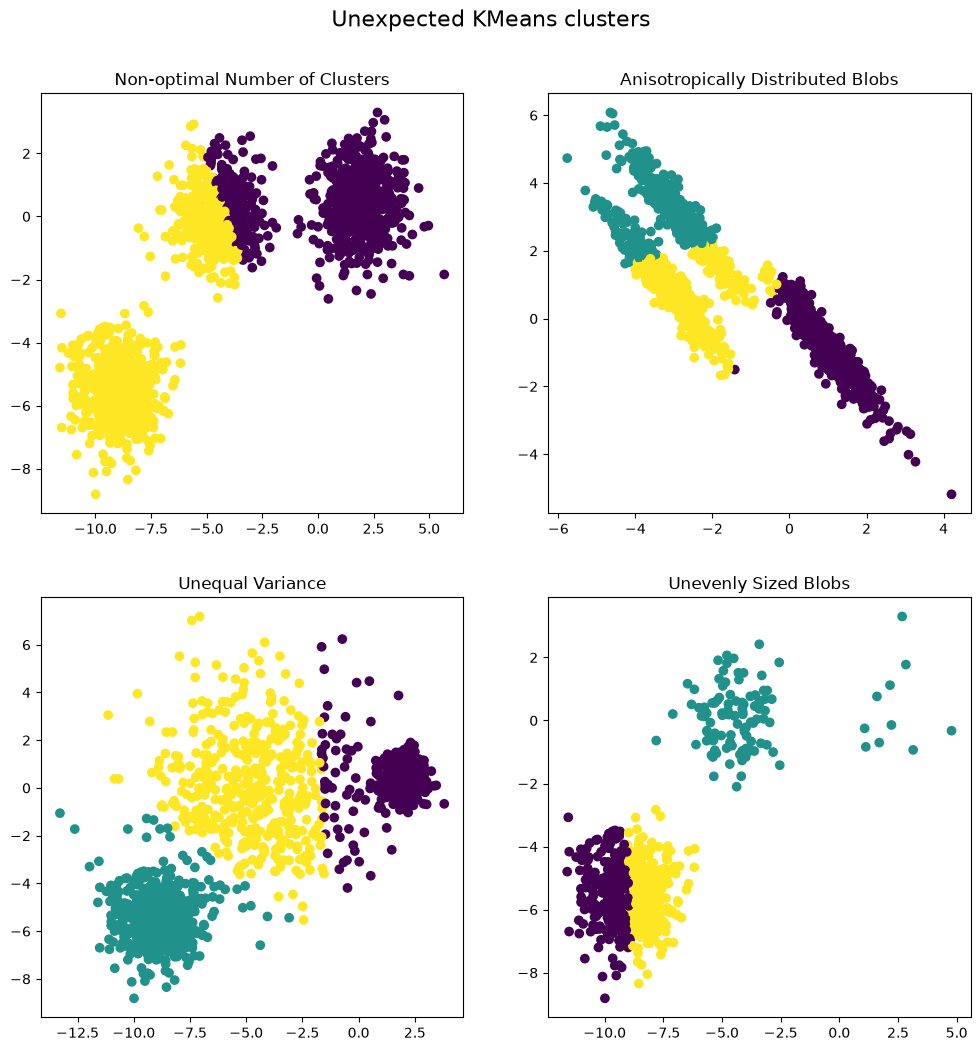

In [21]:
common_params = {
    "n_init": "auto",
    "random_state": random_state,
}

fig, axs = plt.subplots(2, 2, figsize=(12, 12))

y_pred = KMeans(n_clusters=2, **common_params).fit_predict(X)
axs[0, 0].scatter(X[:, 0], X[:, 1], c=y_pred)
axs[0, 0].set_title("Non-optimal Number of Clusters")

y_pred = KMeans(n_clusters=3, **common_params).fit_predict(X_aniso)
axs[0, 1].scatter(X_aniso[:, 0], X_aniso[:, 1], c=y_pred)
axs[0, 1].set_title("Anisotropically Distributed Blobs")

y_pred = KMeans(n_clusters=3, **common_params).fit_predict(X_varied)
axs[1, 0].scatter(X_varied[:, 0], X_varied[:, 1], c=y_pred)
axs[1, 0].set_title("Unequal Variance")

y_pred = KMeans(n_clusters=3, **common_params).fit_predict(X_filtered)
axs[1, 1].scatter(X_filtered[:, 0], X_filtered[:, 1], c=y_pred)
axs[1, 1].set_title("Unevenly Sized Blobs")

plt.suptitle("Unexpected KMeans clusters", fontsize=16).set_y(0.95)
plt.show()

<h4 style="font-weight:600;color:#4f7a9b">3. Possible Solutions</h4>

To remedy the non-optimal number of clusters, set `n_clusters=3`

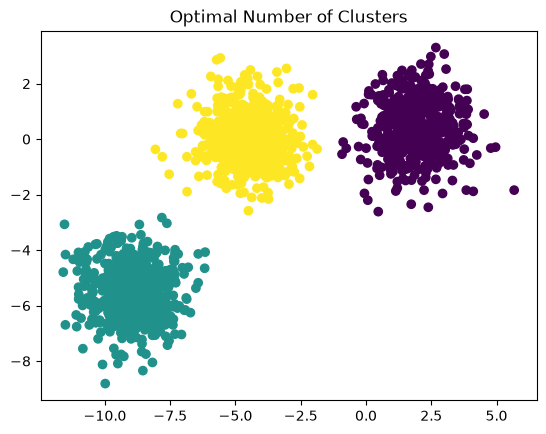

In [23]:
y_pred = KMeans(n_clusters=3, **common_params).fit_predict(X)
plt.scatter(X[:, 0], X[:, 1], c=y_pred)
plt.title("Optimal Number of Clusters")

plt.show()

To deal with unevenly sized blobs, increase the number of random initializations e.g. `n_init=10`

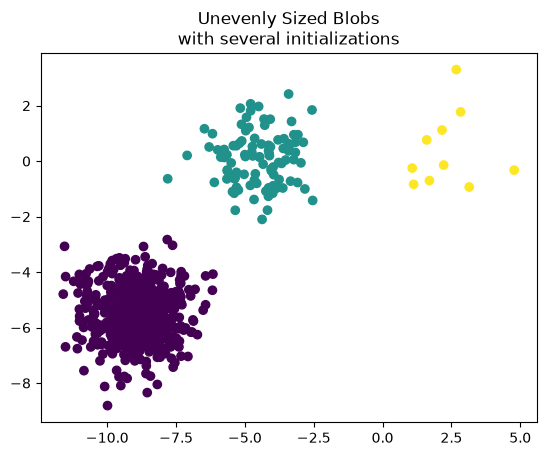

In [24]:
y_pred = KMeans(n_clusters=3, n_init=10, random_state=random_state).fit_predict(X_filtered)
plt.scatter(X_filtered[:, 0], X_filtered[:, 1], c=y_pred)
plt.title("Unevenly Sized Blobs\nwith several initializations")

plt.show()

To deal with the problem of anisotropic and unequal variances, use `GaussianMixture` which does not impose any constraints on their variances.

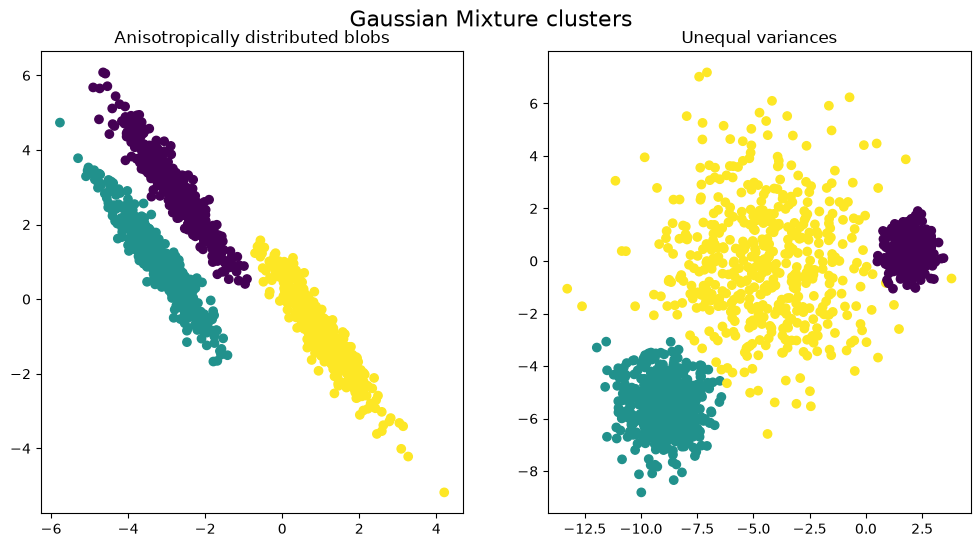

In [28]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))

y_pred = GaussianMixture(n_components=3).fit_predict(X_aniso)
ax1.scatter(X_aniso[:, 0], X_aniso[:, 1], c=y_pred)
ax1.set_title("Anisotropically distributed blobs")

y_pred = GaussianMixture(n_components=3).fit_predict(X_varied)
ax2.scatter(X_varied[:, 0], X_varied[:, 1], c=y_pred)
ax2.set_title("Unequal variances")

plt.suptitle("Gaussian Mixture clusters", fontsize=16).set_y(0.95)
plt.show()